# Fase 4 — Integración y análisis exploratorio de datos

*Hábitos musicales, estado de ánimo, estrés académico y uso de IA en estudiantes de MAC, FES Acatlán*

Este cuaderno integra los tres documentos limpios de la Fase 3 y realiza el análisis exploratorio en tres niveles:

1. **Integración** por seudónimo, con el reporte de registros conservados y perdidos.
2. **EDA individual:** análisis univariado de cada documento y correlaciones bivariadas.
3. **EDA comparado:** evaluación de las hipótesis H1 a H4 (`docs/negocio.md` §4.3), es decir, ánimo frente a estrés y sueño, y ánimo frente a uso de IA.

**Decisiones metodológicas:**

- Con muestras de 16 a 24 casos y variables ordinales, se usan pruebas **no paramétricas o exactas**: correlación de Spearman, Mann-Whitney U, Kruskal-Wallis, exacta de Fisher y ji-cuadrada solo con fines descriptivos cuando hay celdas esperadas pequeñas.
- Cada prueba se acompaña de un **tamaño de efecto**: ρ, correlación biserial de rangos r, razón de momios u ε².
- Como se hacen muchas pruebas a la vez, los valores *p* se ajustan con el procedimiento de **Benjamini-Hochberg** (*q*). Un resultado con *p* < 0.05 pero *q* alto se considera una **señal exploratoria**, no un hallazgo confirmado.
- Los datos son observacionales y auto-reportados: **ningún resultado se interpreta como causal**.
- Las figuras usan una paleta validada para daltonismo y se guardan en `docs/figuras/` para el documento técnico.

In [1]:
# Configuración
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(42)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from datos import PROCESSED
from integracion import cargar_limpios, integrar
from eda import (chi2_independencia, fisher_2x2, kruskal, mann_whitney, matriz_spearman, spearman,
                 tabla_resultados)
import graficos as gr

FIG = RAIZ / "docs" / "figuras"
pd.set_option("display.max_colwidth", 60)
dfs = cargar_limpios()


def mostrar(fig, nombre):
    ruta = gr.guardar(fig, FIG / nombre)
    gr.plt.close(fig)
    display(Image(filename=str(ruta), width=620))

## 1. Integración

### 1.1 Unión interna de los tres documentos

Los documentos se unen por el seudónimo `id` con una **unión interna** (*inner join*) y con validación de correspondencia uno a uno. El resultado es el **núcleo integrado**: los estudiantes que respondieron los tres cuestionarios.

In [2]:
# Unión interna Doc 1 + Doc 2 + Doc 3 y reporte de conservados y perdidos
nucleo, reporte_123 = integrar(dfs, (1, 2, 3))
print("Núcleo integrado:", nucleo.shape)
reporte_123

Núcleo integrado: (19, 133)


,registros,conservados,perdidos,pct_conservado
Doc 1,24,19,5,79.2
Doc 2,19,19,0,100.0
Doc 3,24,19,5,79.2


Se conservan **19 estudiantes**, todos los del Documento 2. Los Documentos 1 y 3 pierden 5 registros cada uno, correspondientes a quienes no respondieron el cuestionario de bienestar.

### 1.2 Integración complementaria: Documentos 1 y 3

Las preguntas que relacionan la música con la IA no necesitan el Documento 2. Para ellas se construye un segundo conjunto integrado, que aprovecha a los 24 estudiantes.

In [3]:
# Unión interna Doc 1 + Doc 3
musica_ia, reporte_13 = integrar(dfs, (1, 3))
print("Conjunto música + IA:", musica_ia.shape)
reporte_13

Conjunto música + IA: (24, 97)


,registros,conservados,perdidos,pct_conservado
Doc 1,24,24,0,100.0
Doc 3,24,24,0,100.0


Gracias a la corrección de la cuenta de diez dígitos (Fase 3), los 24 registros de ambos documentos se vinculan sin pérdidas.

### 1.3 ¿Los registros perdidos difieren de los conservados?

Si los 5 estudiantes que no están en el núcleo fueran sistemáticamente distintos, el núcleo estaría sesgado. Se comparan sus hábitos musicales y su reporte de mejora de ánimo con los del resto del Documento 1.

In [4]:
# Comparación de conservados (núcleo) frente a perdidos en el Documento 1
d1 = dfs[1].assign(en_nucleo=dfs[1]["id"].isin(nucleo["id"]).astype(int))
tabla_resultados([mann_whitney(d1, "en_nucleo", "m_horas", "Sesgo"),
                  fisher_2x2(d1, "en_nucleo", "mejora_animo", "Sesgo")])

,hipótesis,prueba,x,y,n,detalle,estadístico,p,q_BH,efecto,medida_efecto
0,Sesgo,Mann-Whitney,en_nucleo,m_horas,24,n=5/19; mediana 5.00 vs 4.00,28.5,0.1853,0.3706,-0.400,r_rb
1,Sesgo,Fisher exacta,en_nucleo,mejora_animo,20,"tabla [[0, 3], [3, 14]]",NaN,1.0000,1.0000,0.592,OR


No hay diferencias apreciables entre ambos grupos en las horas de escucha (*p* = 0.19) ni en la mejora de ánimo (*p* = 1.0). No se detecta un sesgo de selección evidente, aunque con 5 casos perdidos la prueba tiene poca potencia.

In [5]:
# Guardado de los conjuntos integrados
nucleo.to_csv(PROCESSED / "integrado_123.csv", index=False, encoding="utf-8")
musica_ia.to_csv(PROCESSED / "integrado_13.csv", index=False, encoding="utf-8")
print("Guardados: integrado_123.csv", nucleo.shape, "| integrado_13.csv", musica_ia.shape)

Guardados: integrado_123.csv (19, 133) | integrado_13.csv (24, 97)


## 2. EDA individual: análisis univariado

### 2.1 Hábitos musicales (Documento 1, n = 24)

        count  mean   std   min   25%  50%  75%   max
fuente                                               
IA       24.0  1.91  1.82  0.08  1.00  1.5  2.0   8.0
Música   24.0  4.62  3.38  0.00  2.38  4.0  5.5  15.0


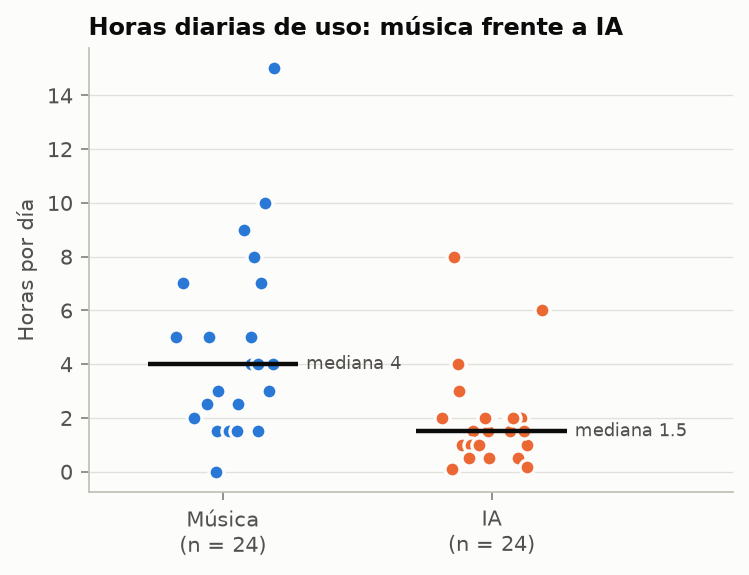

In [6]:
# Horas diarias de música y de IA (misma unidad, un solo eje)
horas = pd.concat([
    pd.DataFrame({"fuente": "Música", "horas": dfs[1]["m_horas"]}),
    pd.DataFrame({"fuente": "IA", "horas": dfs[3]["ia_horas"]}),
])
print(horas.groupby("fuente")["horas"].describe().round(2))
fig, ax = gr.puntos_por_grupo(horas, "fuente", "horas", ["Música", "IA"], ["Música", "IA"],
                              "Horas diarias de uso: música frente a IA", "Horas por día")
mostrar(fig, "f1_horas_musica_ia.png")

Los estudiantes reportan una **mediana de 4 horas diarias de música**, frente a 1.5 horas de IA. La dispersión de la música es mucho mayor: va de 0 a 15 horas, mientras que el rango intercuartílico de la IA es de 1 a 2 horas.

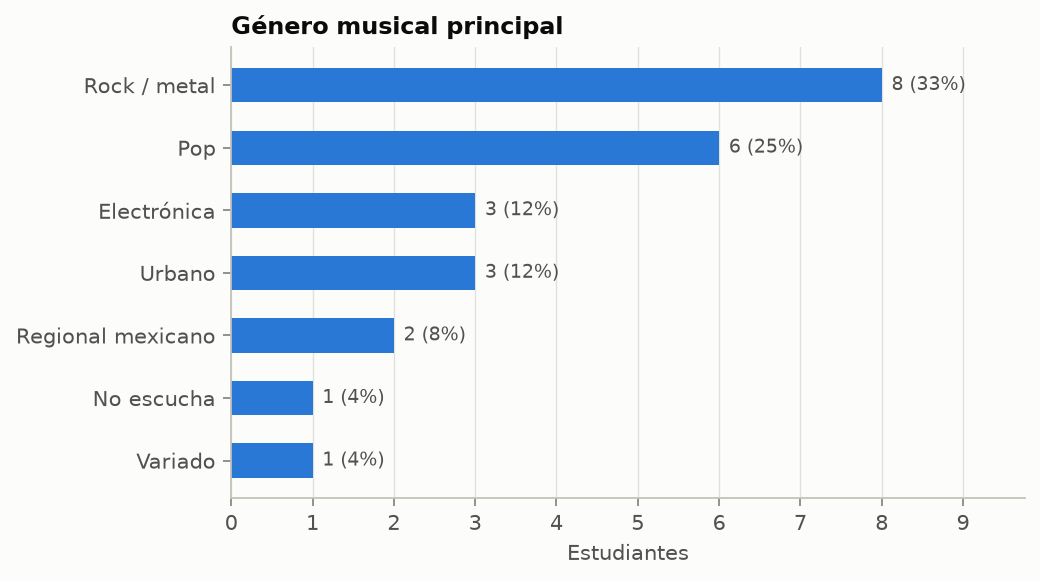

In [7]:
# Género musical principal
gen = dfs[1]["m_genero_grupo"].map({"rock_metal": "Rock / metal", "pop": "Pop", "electronica": "Electrónica",
                                     "urbano": "Urbano", "regional": "Regional mexicano", "variado": "Variado",
                                     "no_escucha": "No escucha"}).value_counts()
fig, ax = gr.barras_h(gen, "Género musical principal", "Estudiantes", total=len(dfs[1]))
mostrar(fig, "f2_generos.png")

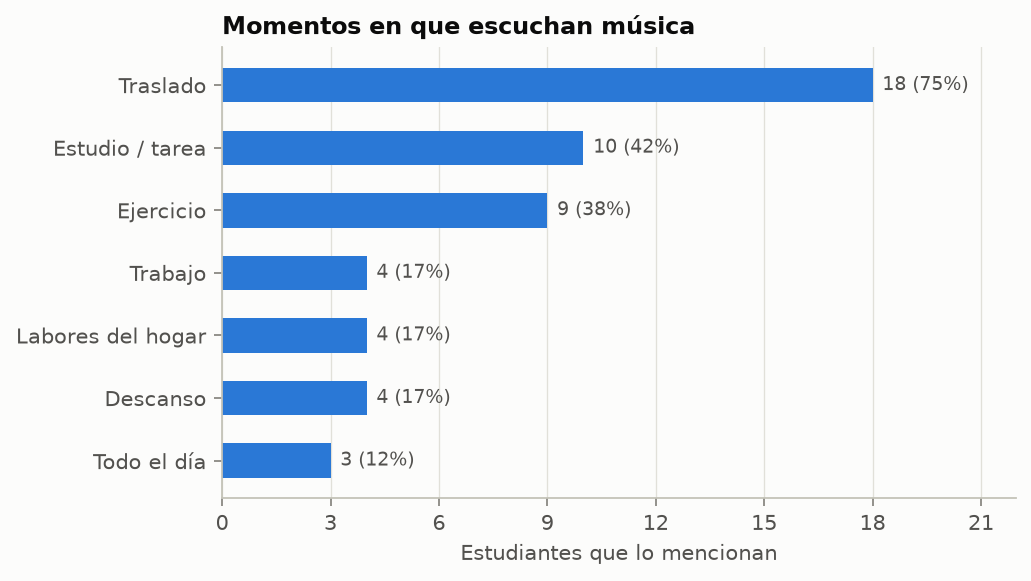

In [8]:
# Momentos de escucha (multirrespuesta)
mom = dfs[1][[c for c in dfs[1] if c.startswith("mom_")]].sum()
mom.index = ["Estudio / tarea", "Traslado", "Ejercicio", "Descanso", "Labores del hogar", "Trabajo", "Todo el día"]
fig, ax = gr.barras_h(mom, "Momentos en que escuchan música", "Estudiantes que lo mencionan", total=len(dfs[1]))
mostrar(fig, "f3_momentos.png")

El **rock/metal** (8) y el **pop** (6) son los géneros principales más frecuentes. El momento de escucha más mencionado es el **traslado** (18 de 24, 75 %), seguido del estudio o la tarea (10) y el ejercicio (9). Este resultado conecta con la problemática: la música acompaña sobre todo los trayectos.

### 2.2 Bienestar (núcleo integrado, n = 19)

In [9]:
# Distribución de las variables de bienestar codificadas (conteos por nivel)
vars_b = {"b_desanimo_cod": "Desánimo (0-4)", "b_irritabilidad_cod": "Irritabilidad (0-4)",
          "b_sueno_calidad_cod": "Calidad de sueño (0-3)", "b_concentracion_dif_cod": "Dificultad de concentración (0-3)",
          "b_traslado_impacto_cod": "Impacto del traslado (0-3)", "b_apoyo_social_cod": "Apoyo social (0-3)"}
tabla_b = pd.DataFrame({v: nucleo[k].value_counts().sort_index() for k, v in vars_b.items()}).T.fillna(0).astype(int)
tabla_b.columns = [f"nivel {int(c)}" for c in tabla_b.columns]
tabla_b["mediana"] = [nucleo[k].median() for k in vars_b]
tabla_b

,nivel 0,nivel 1,nivel 2,nivel 3,nivel 4,mediana
Desánimo (0-4),0,5,3,3,7,3.0
Irritabilidad (0-4),0,11,2,1,5,1.0
Calidad de sueño (0-3),5,6,5,3,0,1.0
Dificultad de concentración (0-3),3,9,1,6,0,1.0
Impacto del traslado (0-3),1,8,4,6,0,2.0
Apoyo social (0-3),0,2,7,10,0,3.0


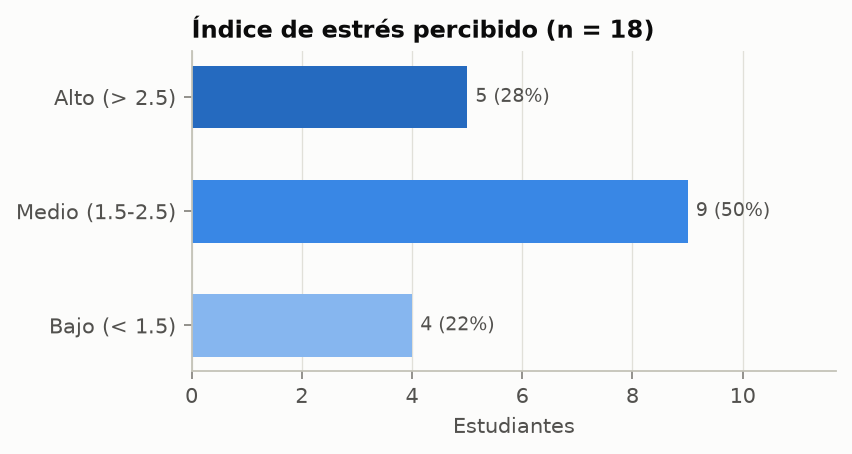

In [10]:
# Índice de estrés percibido por nivel (rampa ordinal azul: más oscuro = más estrés)
niveles = nucleo["iep_nivel"].value_counts().reindex(["bajo", "medio", "alto"]).fillna(0)
fig, ax = gr.plt.subplots(figsize=(5.2, 2.6))
ax.barh(["Bajo (< 1.5)", "Medio (1.5-2.5)", "Alto (> 2.5)"], niveles.values,
        color=gr.ORDINAL_AZUL[:3], height=0.55)
for i, v in enumerate(niveles.values):
    ax.text(v + 0.15, i, f"{int(v)} ({v / niveles.sum():.0%})", va="center", fontsize=8.5, color=gr.TINTA_2)
ax.grid(axis="y", visible=False); ax.set_xlim(0, niveles.max() * 1.3)
ax.set_xlabel("Estudiantes"); ax.set_title("Índice de estrés percibido (n = 18)")
mostrar(fig, "f4_iep.png")

Los indicadores de bienestar muestran un panorama de **carga emocional apreciable**:

- **Desánimo:** la mediana es 3 en la escala de 0 a 4, y 7 de 18 estudiantes lo reportan "muy frecuentemente" o "casi siempre".
- **Sueño:** 11 de 19 lo califican como malo o algo malo.
- **Estrés percibido:** 14 de 18 estudiantes tienen un IEP medio o alto.
- **Apoyo social:** en contraste, es alto para la mayoría (mediana 3 de 3).

### 2.3 Uso de IA (Documento 3, n = 24)

In [11]:
# Herramientas y modalidad de uso
from codificacion import HERRAMIENTAS
herr = dfs[3][list(HERRAMIENTAS)].sum().sort_values(ascending=False)
herr.index = [i.replace("ia_", "").capitalize() for i in herr.index]
display(herr.rename("menciones").to_frame().T)
display(dfs[3]["ia_guia_vs_atajo_cod"].value_counts(dropna=False).rename("estudiantes").to_frame().T)
display(dfs[3]["ia_estres_cod"].map({-1: "aumenta", 0: "sin efecto", 1: "disminuye"}).value_counts()
        .rename("efecto percibido en el estrés").to_frame().T)

,Gemini,Chatgpt,Claude,Deepseek,Notebooklm,Copilot,Qwen
menciones,15.0,11.0,8.0,3.0,3.0,2.0,1.0


ia_guia_vs_atajo_cod,ambas,guia,atajo,NaN
estudiantes,13,8,2,1


ia_estres_cod,disminuye,sin efecto,aumenta
efecto percibido en el estrés,20,3,1


**Gemini** (15) y **ChatGPT** (11) son las herramientas más usadas, y la mayoría de los estudiantes combina una o dos. Más de la mitad usa la IA a la vez como guía y como atajo (13 de 23). Casi todos perciben que la IA **disminuye** su estrés (20 de 24), así que esta variable tiene muy poca variabilidad.

## 3. EDA individual: análisis bivariado y correlaciones

La matriz siguiente resume las correlaciones de Spearman entre las variables ordinales y cuantitativas del núcleo integrado. Cada par usa los casos completos disponibles. El asterisco indica *p* < 0.05 **sin corregir**, por lo que debe leerse como una guía exploratoria.

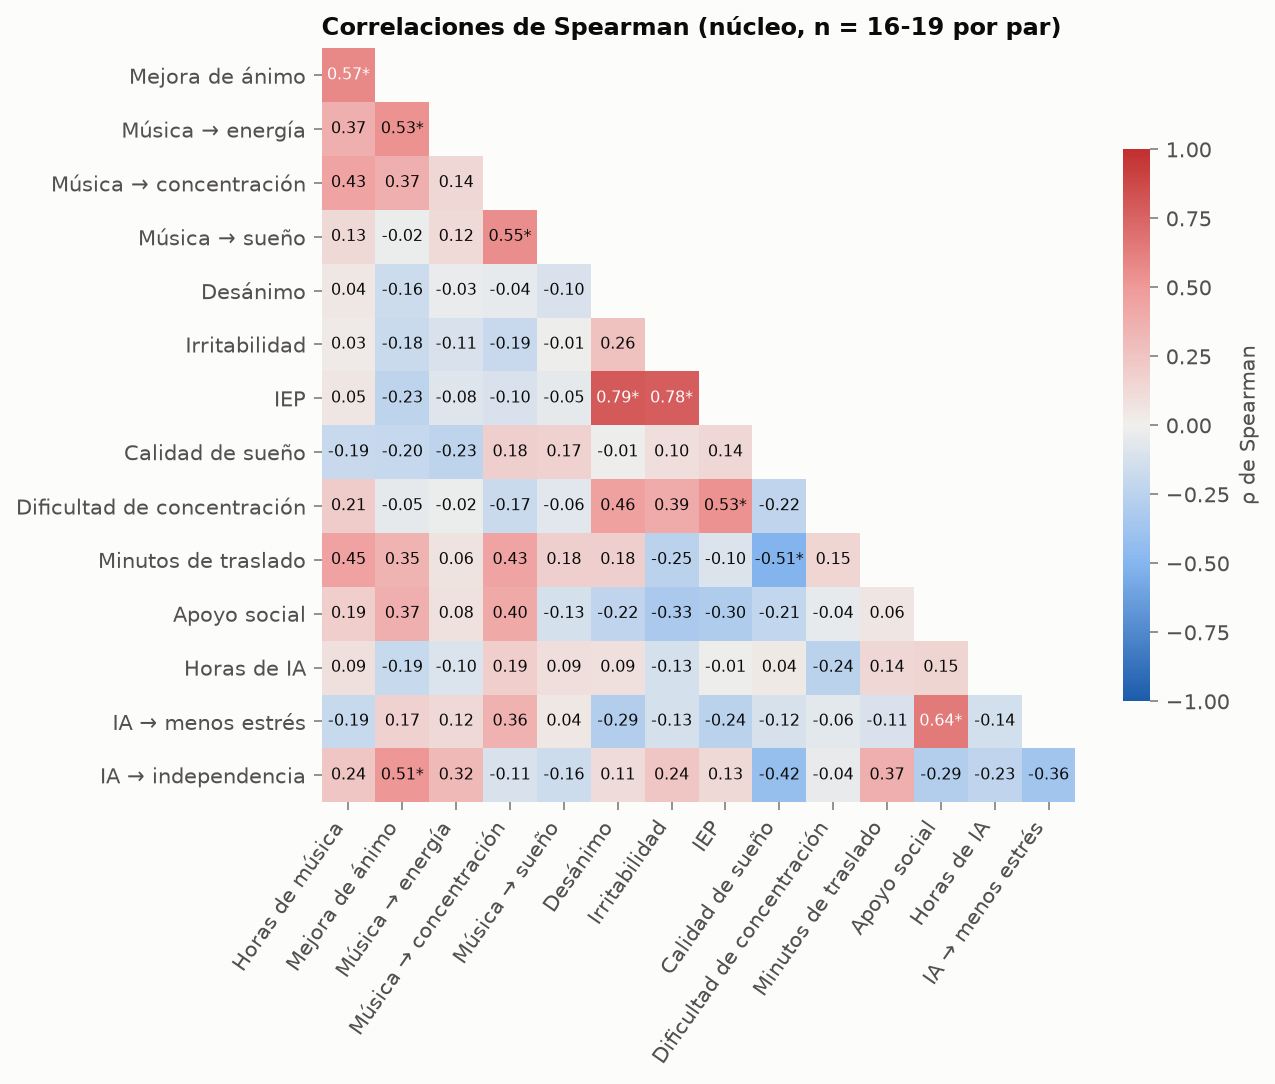

In [12]:
# Matriz de correlación de Spearman (núcleo integrado)
etiquetas = {"m_horas": "Horas de música", "mejora_animo": "Mejora de ánimo", "m_energia_cod": "Música → energía",
             "m_concentracion_cod": "Música → concentración", "m_sueno_cod": "Música → sueño",
             "b_desanimo_cod": "Desánimo", "b_irritabilidad_cod": "Irritabilidad", "iep": "IEP",
             "b_sueno_calidad_cod": "Calidad de sueño", "b_concentracion_dif_cod": "Dificultad de concentración",
             "b_traslado_min_cod": "Minutos de traslado", "b_apoyo_social_cod": "Apoyo social",
             "ia_horas": "Horas de IA", "ia_estres_cod": "IA → menos estrés", "ia_independencia_cod": "IA → independencia"}
rho, pv = matriz_spearman(nucleo, list(etiquetas))
fig, ax = gr.heatmap_spearman(rho, pv, etiquetas, "Correlaciones de Spearman (núcleo, n = 16-19 por par)")
mostrar(fig, "f5_spearman.png")

In [13]:
# Pares con |rho| >= 0.4 (excluye pares de variables que comparten construcción, p. ej. IEP con sus componentes)
componentes = {("iep", "b_desanimo_cod"), ("iep", "b_irritabilidad_cod")}
pares = []
for i, a in enumerate(rho.index):
    for b in rho.index[:i]:
        if abs(rho.loc[a, b]) >= 0.4 and (a, b) not in componentes and (b, a) not in componentes:
            pares.append({"variable_1": etiquetas[b], "variable_2": etiquetas[a], "rho": round(rho.loc[a, b], 2),
                          "p": round(pv.loc[a, b], 4)})
pd.DataFrame(pares).sort_values("rho", key=abs, ascending=False)

,variable_1,variable_2,rho,p
10,Apoyo social,IA → menos estrés,0.64,0.0031
0,Horas de música,Mejora de ánimo,0.57,0.0167
3,Música → concentración,Música → sueño,0.55,0.0185
5,IEP,Dificultad de concentración,0.53,0.0236
1,Mejora de ánimo,Música → energía,0.53,0.0286
11,Mejora de ánimo,IA → independencia,0.51,0.0419
8,Calidad de sueño,Minutos de traslado,-0.51,0.0269
4,Desánimo,Dificultad de concentración,0.46,0.0544
6,Horas de música,Minutos de traslado,0.45,0.0536
2,Horas de música,Música → concentración,0.43,0.0716


Destacan cinco patrones:

- **Validez del IEP.** El índice se asocia con la dificultad de concentración (ρ = 0.53), una relación esperable que respalda su coherencia como indicador indirecto de estrés.
- **Traslado y sueño.** A más minutos de traslado, peor calidad de sueño (ρ = −0.51, *p* = 0.027). Este dato respalda un elemento central de la problemática.
- **Intensidad de escucha.** Las horas de música se asocian con reportar mejora de ánimo (ρ = 0.57) y con percibir que la música ayuda a concentrarse (ρ = 0.43).
- **Apoyo social e IA.** Quienes tienen más apoyo social también perciben con más fuerza que la IA reduce su estrés (ρ = 0.64, *p* = 0.003). No se había planteado como hipótesis y debe tratarse como un hallazgo a confirmar.
- **Música y bienestar general.** Ninguna de las variables de música (horas, mejora, energía, concentración, sueño) se correlaciona con los indicadores generales de bienestar del Documento 2 (desánimo, irritabilidad, IEP, calidad de sueño): todas tienen |ρ| ≤ 0.23.

Con alrededor de 100 pares evaluados, se esperarían unos 5 resultados con *p* < 0.05 solo por azar. Por eso estos patrones son orientativos.

## 4. EDA comparado: evaluación de las hipótesis

La tabla reúne todas las pruebas de las hipótesis H1 a H4 sobre el núcleo integrado, junto con una prueba adicional que usa el Documento 1 completo. La columna *q* aplica la corrección de Benjamini-Hochberg sobre el conjunto de pruebas.

In [14]:
# Pruebas de hipótesis (núcleo integrado salvo indicación)
guia = lambda df: df.assign(guia=(df["ia_guia_vs_atajo_cod"] == "guia").astype(float)
                             .where(df["ia_guia_vs_atajo_cod"].notna()))
nucleo_g = guia(nucleo)
genero3 = nucleo.assign(genero3=nucleo["m_genero_grupo"].where(nucleo["m_genero_grupo"].isin(["pop", "rock_metal"]), "otros"))
pruebas = [
    # H1: mejora de ánimo con música frente a desánimo, irritabilidad e IEP
    mann_whitney(nucleo, "mejora_animo", "b_desanimo_cod", "H1"),
    mann_whitney(nucleo, "mejora_animo", "b_irritabilidad_cod", "H1"),
    mann_whitney(nucleo, "mejora_animo", "iep", "H1"),
    mann_whitney(nucleo, "mejora_animo", "b_sueno_calidad_cod", "H1"),
    mann_whitney(nucleo, "m_maneja_emociones_cod", "iep", "H1"),
    # H2: horas y momentos de escucha frente a ánimo, concentración y sueño
    mann_whitney(dfs[1], "mejora_animo", "m_horas", "H2 (Doc 1)"),
    spearman(nucleo, "m_horas", "iep", "H2"),
    spearman(nucleo, "m_horas", "b_sueno_calidad_cod", "H2"),
    spearman(nucleo, "m_horas", "b_concentracion_dif_cod", "H2"),
    spearman(nucleo, "m_horas", "m_concentracion_cod", "H2"),
    spearman(nucleo, "m_horas", "m_energia_cod", "H2"),
    fisher_2x2(nucleo, "mom_estudio", "mejora_animo", "H2"),
    fisher_2x2(nucleo, "mom_traslado", "mejora_animo", "H2"),
    fisher_2x2(nucleo, "mom_ejercicio", "mejora_animo", "H2"),
    # H3: géneros musicales y estados positivos
    kruskal(nucleo, "m_genero_grupo", "iep", "H3"),
    chi2_independencia(genero3, "genero3", "mejora_animo", "H3"),
    mann_whitney(nucleo, "emo_pop", "iep", "H3"),
    mann_whitney(nucleo, "emo_rock_metal", "iep", "H3"),
    # H4: uso de IA
    spearman(nucleo, "ia_horas", "iep", "H4"),
    mann_whitney(nucleo_g, "guia", "iep", "H4"),
    spearman(nucleo, "ia_estres_cod", "iep", "H4"),
    spearman(nucleo, "ia_independencia_cod", "iep", "H4"),
    fisher_2x2(nucleo_g, "guia", "mejora_animo", "H4"),
]
resultados = tabla_resultados(pruebas)
resultados.to_csv(RAIZ / "docs" / "pruebas_hipotesis.csv", index=False, encoding="utf-8-sig")
resultados

,hipótesis,prueba,x,y,n,detalle,estadístico,p,q_BH,efecto,medida_efecto
0,H1,Mann-Whitney,mejora_animo,b_desanimo_cod,16,n=3/13; mediana 4.00 vs 3.00,15.000,0.5730,0.8237,-0.231,r_rb
1,H1,Mann-Whitney,mejora_animo,b_irritabilidad_cod,17,n=3/14; mediana 2.00 vs 1.00,16.000,0.5188,0.7955,-0.238,r_rb
2,H1,Mann-Whitney,mejora_animo,iep,16,n=3/13; mediana 2.50 vs 2.00,13.000,0.4119,0.7955,-0.333,r_rb
3,H1,Mann-Whitney,mejora_animo,b_sueno_calidad_cod,17,n=3/14; mediana 2.00 vs 1.00,15.000,0.4698,0.7955,-0.286,r_rb
4,H1,Mann-Whitney,m_maneja_emociones_cod,iep,17,n=2/15; mediana 1.75 vs 2.50,20.000,0.4948,0.7955,0.333,r_rb
5,H2 (Doc 1),Mann-Whitney,mejora_animo,m_horas,20,n=3/17; mediana 1.50 vs 5.00,48.000,0.0192,0.3520,0.882,r_rb
6,H2,Spearman,m_horas,iep,18,NaN,0.050,0.8440,0.9244,0.050,rho
7,H2,Spearman,m_horas,b_sueno_calidad_cod,19,NaN,-0.185,0.4476,0.7955,-0.185,rho
8,H2,Spearman,m_horas,b_concentracion_dif_cod,19,NaN,0.205,0.3996,0.7955,0.205,rho
9,H2,Spearman,m_horas,m_concentracion_cod,18,NaN,0.434,0.0716,0.5492,0.434,rho


In [15]:
# Resumen por hipótesis: pruebas, señales con p < 0.05 y resultados con q < 0.05
resultados.assign(h=resultados["hipótesis"].str[:2]).groupby("h").agg(
    pruebas=("p", "size"), p_menor_005=("p", lambda s: int((s < 0.05).sum())),
    q_menor_005=("q_BH", lambda s: int((s < 0.05).sum())), q_minimo=("q_BH", "min"))

,pruebas,p_menor_005,q_menor_005,q_minimo
h,,,,
H1,5,0,0,0.7955
H2,9,1,0,0.3520
H3,4,0,0,0.7955
H4,5,1,0,0.3520


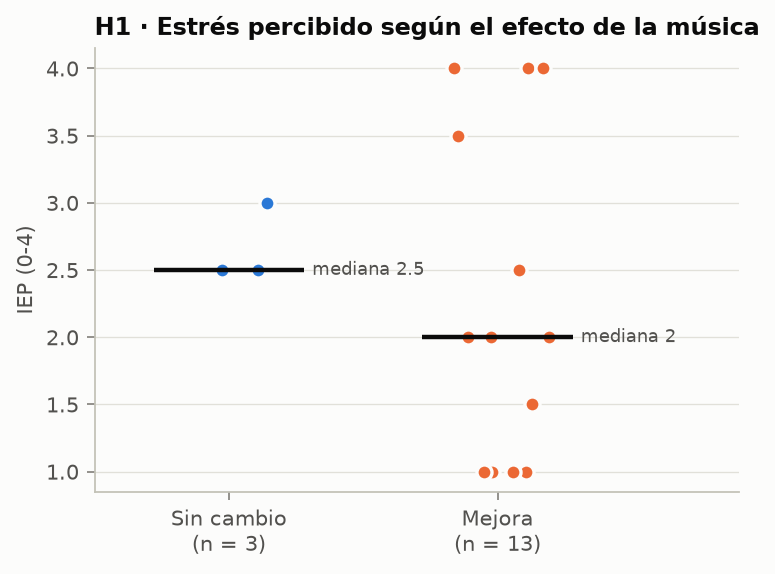

In [16]:
# Figura H1: IEP según si la música mejora el ánimo
fig, ax = gr.puntos_por_grupo(nucleo, "mejora_animo", "iep", [0.0, 1.0], ["Sin cambio", "Mejora"],
                              "H1 · Estrés percibido según el efecto de la música", "IEP (0-4)")
mostrar(fig, "f6_h1_iep_mejora.png")

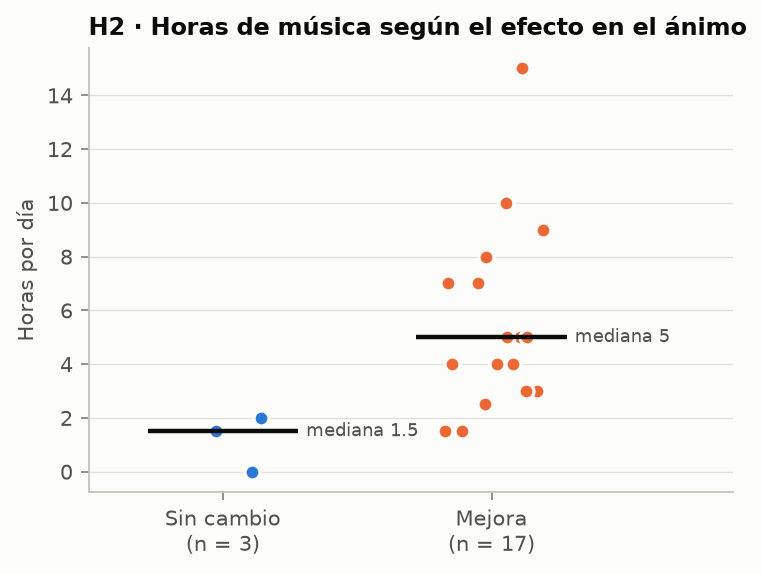

In [17]:
# Figura H2: horas de música según si la música mejora el ánimo (Documento 1)
fig, ax = gr.puntos_por_grupo(dfs[1], "mejora_animo", "m_horas", [0.0, 1.0], ["Sin cambio", "Mejora"],
                              "H2 · Horas de música según el efecto en el ánimo", "Horas por día")
mostrar(fig, "f7_h2_horas_mejora.png")

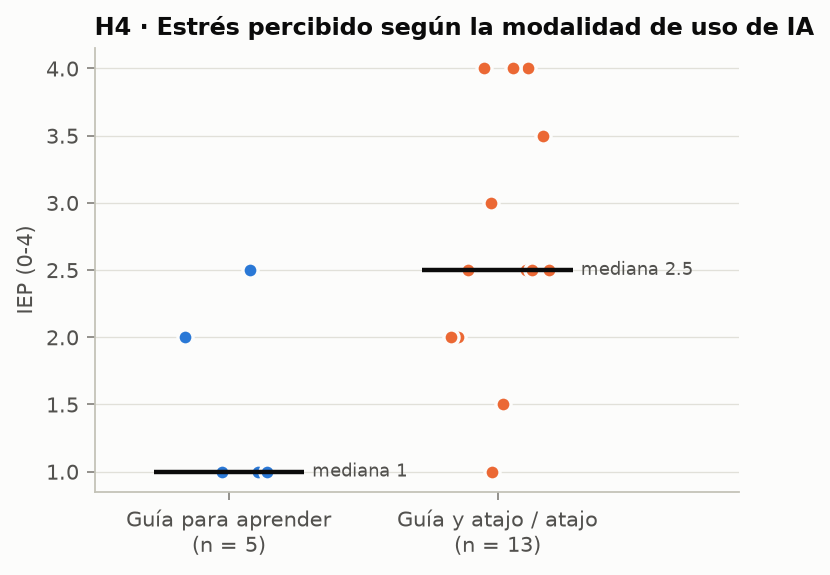

In [18]:
# Figura H4: IEP según la modalidad de uso de IA
mod = nucleo.assign(modalidad=nucleo["ia_guia_vs_atajo_cod"].replace({"atajo": "ambas"}))
fig, ax = gr.puntos_por_grupo(mod, "modalidad", "iep", ["guia", "ambas"], ["Guía para aprender", "Guía y atajo / atajo"],
                              "H4 · Estrés percibido según la modalidad de uso de IA", "IEP (0-4)")
mostrar(fig, "f8_h4_iep_modalidad.png")

### 4.1 Moderación exploratoria por uso de IA (H4)

Para explorar si el uso de IA modifica la relación entre la música y el estrés, se divide el núcleo según la mediana de horas de IA (1.5 h) y se calcula la correlación entre horas de música e IEP en cada estrato. Con 7 a 11 casos por estrato, el resultado es **solo descriptivo**: no hay potencia para probar formalmente una interacción.

,estrato,n,rho,p
0,bajo,11,0.360,0.277
1,alto,7,-0.574,0.178


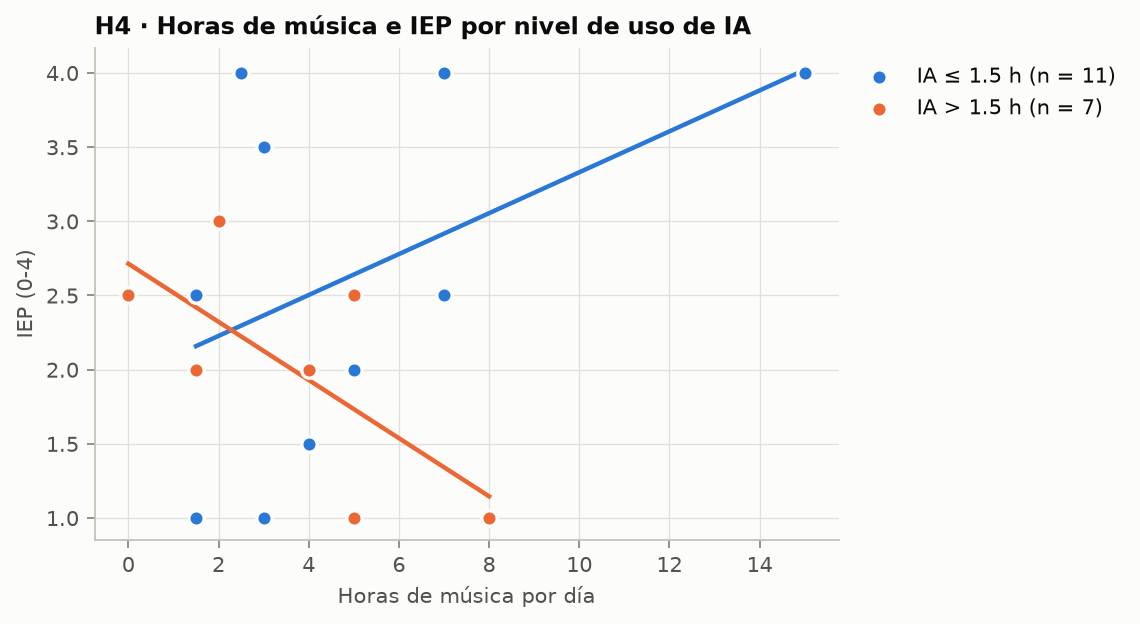

In [19]:
# Correlación horas de música - IEP dentro de cada estrato de uso de IA
mediana_ia = nucleo["ia_horas"].median()
estratos = nucleo.assign(uso_ia=np.where(nucleo["ia_horas"] > mediana_ia, "alto", "bajo"))
filas = [dict(spearman(estratos[estratos["uso_ia"] == e], "m_horas", "iep", f"H4 · uso de IA {e}"), estrato=e)
         for e in ["bajo", "alto"]]
display(pd.DataFrame(filas)[["estrato", "n", "estadístico", "p"]].rename(columns={"estadístico": "rho"}).round(3))
fig, ax = gr.dispersion_por_grupo(estratos, "m_horas", "iep", "uso_ia", ["bajo", "alto"],
                                  [f"IA ≤ {mediana_ia:g} h", f"IA > {mediana_ia:g} h"],
                                  "H4 · Horas de música e IEP por nivel de uso de IA", "Horas de música por día", "IEP (0-4)")
mostrar(fig, "f9_h4_moderacion.png")

### 4.2 Análisis complementario con los Documentos 1 y 3 (n = 24)

In [20]:
# Música e IA sin el Documento 2; sensibilidad excluyendo el registro marcado como posible copia
mi_g = guia(musica_ia)
complementario = tabla_resultados([
    spearman(musica_ia, "ia_horas", "m_horas", "1+3"),
    spearman(musica_ia, "ia_horas", "m_concentracion_cod", "1+3"),
    mann_whitney(musica_ia, "mejora_animo", "ia_horas", "1+3"),
    fisher_2x2(mi_g, "guia", "mejora_animo", "1+3"),
    fisher_2x2(mi_g[mi_g["sospecha_copia"] != 1], "guia", "mejora_animo", "1+3 sin posible copia"),
    spearman(musica_ia[musica_ia["sospecha_copia"] != 1], "ia_horas", "m_horas", "1+3 sin posible copia"),
])
complementario

,hipótesis,prueba,x,y,n,detalle,estadístico,p,q_BH,efecto,medida_efecto
0,1+3,Spearman,ia_horas,m_horas,24,NaN,0.083,0.6993,0.7092,0.083,rho
1,1+3,Spearman,ia_horas,m_concentracion_cod,23,NaN,0.182,0.4056,0.7092,0.182,rho
2,1+3,Mann-Whitney,mejora_animo,ia_horas,20,n=3/17; mediana 2.00 vs 1.50,19.500,0.5547,0.7092,-0.235,r_rb
3,1+3,Fisher exacta,guia,mejora_animo,19,"tabla [[3, 10], [0, 6]]",NaN,0.5170,0.7092,4.333,OR
4,1+3 sin posible copia,Fisher exacta,guia,mejora_animo,19,"tabla [[3, 10], [0, 6]]",NaN,0.5170,0.7092,4.333,OR
5,1+3 sin posible copia,Spearman,ia_horas,m_horas,23,NaN,0.082,0.7092,0.7092,0.082,rho


Con 24 estudiantes tampoco aparece relación entre el tiempo dedicado a la música y el dedicado a la IA, ni entre la modalidad de uso de IA y la mejora de ánimo. Excluir el registro marcado como posible copia no cambia los resultados.

## 5. Análisis de sensibilidad: valores atípicos

Se repiten las pruebas con señal exploratoria excluyendo a los estudiantes del núcleo con algún valor atípico (horas de música, horas de IA o minutos de traslado).

In [21]:
# Repetición sin atípicos
sin_atipicos = nucleo[(nucleo["m_horas_atipico"] != 1) & (nucleo["ia_horas_atipico"] != 1)
                      & (nucleo["b_traslado_min_atipico"] != 1)]
print("Casos del núcleo sin atípicos:", len(sin_atipicos), "de", len(nucleo))
d1_sin = dfs[1][dfs[1]["m_horas_atipico"] != 1]
tabla_resultados([
    mann_whitney(d1_sin, "mejora_animo", "m_horas", "H2 (Doc 1) sin atípicos"),
    spearman(sin_atipicos, "m_horas", "m_concentracion_cod", "H2 sin atípicos"),
    spearman(sin_atipicos, "m_horas", "m_energia_cod", "H2 sin atípicos"),
    mann_whitney(guia(sin_atipicos), "guia", "iep", "H4 sin atípicos"),
])

Casos del núcleo sin atípicos: 16 de 19


,hipótesis,prueba,x,y,n,detalle,estadístico,p,q_BH,efecto,medida_efecto
0,H2 (Doc 1) sin atípicos,Mann-Whitney,mejora_animo,m_horas,19,n=3/16; mediana 1.50 vs 4.50,45.000,0.0211,0.0559,0.875,r_rb
1,H2 sin atípicos,Spearman,m_horas,m_concentracion_cod,15,NaN,0.265,0.3399,0.3399,0.265,rho
2,H2 sin atípicos,Spearman,m_horas,m_energia_cod,16,NaN,0.514,0.0419,0.0559,0.514,rho
3,H4 sin atípicos,Mann-Whitney,guia,iep,16,n=11/5; mediana 2.50 vs 1.00,9.000,0.0367,0.0559,-0.673,r_rb


## 6. Valores preliminares de los indicadores clave

Se calculan con las definiciones de `docs/negocio.md` §9.4 como referencia para el tablero (Fase 6). Cada indicador muestra su *n*.

In [22]:
# KPI 1 y 2 (Documento 1)
mv = dfs[1]["mejora_animo"].dropna()
print(f"KPI 1 · % que reporta mejora de ánimo con música: {mv.mean():.0%} ({int(mv.sum())} de {len(mv)})")
kpi2 = dfs[1].groupby("m_horas_nivel")["m_horas"].agg(n="count", media="mean", mediana="median").reindex(["baja", "media", "alta"])
display(kpi2.round(2))

KPI 1 · % que reporta mejora de ánimo con música: 85% (17 de 20)


,n,media,mediana
m_horas_nivel,,,
baja,5,1.20,1.5
media,9,3.22,3.0
alta,10,7.60,7.0


In [23]:
# KPI 3 (géneros con n >= 3 en el núcleo), KPI 4 (IEP por perfil de horas) y KPI 5 (IA por nivel de IEP)
k3 = nucleo.groupby("m_genero_grupo").agg(n=("id", "size"), pct_mejora=("mejora_animo", "mean"),
                                          iep_medio=("iep", "mean"))
display(k3[k3["n"] >= 3].sort_values("pct_mejora", ascending=False).round(2))
k4 = nucleo.groupby("m_horas_nivel").agg(n=("id", "size"), iep_medio=("iep", "mean"), iep_mediana=("iep", "median"))
display(k4.reindex(["baja", "media", "alta"]).round(2))
k5 = mod.groupby("iep_nivel").agg(n=("id", "size"), horas_ia_media=("ia_horas", "mean"),
                                  horas_ia_mediana=("ia_horas", "median"),
                                  pct_guia=("modalidad", lambda s: (s == "guia").mean()))
display(k5.reindex(["bajo", "medio", "alto"]).round(2))

,n,pct_mejora,iep_medio
m_genero_grupo,,,
urbano,3,1.00,2.17
pop,6,0.83,2.67
rock_metal,4,0.67,2.50


,n,iep_medio,iep_mediana
m_horas_nivel,,,
baja,5,2.10,2.5
media,7,2.50,2.5
alta,7,2.43,2.5


,n,horas_ia_media,horas_ia_mediana,pct_guia
iep_nivel,,,,
bajo,4,1.15,1.25,0.75
medio,9,1.96,1.50,0.22
alto,5,1.30,1.50,0.00


## 6b. Análisis descriptivo de texto libre (NLTK)

Las preguntas abiertas que no se codificaron en la Fase 3 (artistas favoritos, experiencias con la música y reglas, verificación y cambios en el estudio con IA) se resumen con NLTK. Primero se normaliza el texto. Después, `RegexpTokenizer` extrae palabras de al menos 3 letras y se descartan las palabras vacías con una lista propia en español, para no descargar corpus externos. Por último, se calculan frecuencias (`FreqDist`) y bigramas.

Además de la frecuencia total, se reporta en cuántas respuestas aparece cada palabra. Solo se muestran términos que aparecen al menos 2 veces. El análisis es descriptivo y no se relaciona con las hipótesis.

,bad bunny,alan walker,morat,the weeknd,latin mafia,luis miguel
menciones,4,2,2,2,2,2


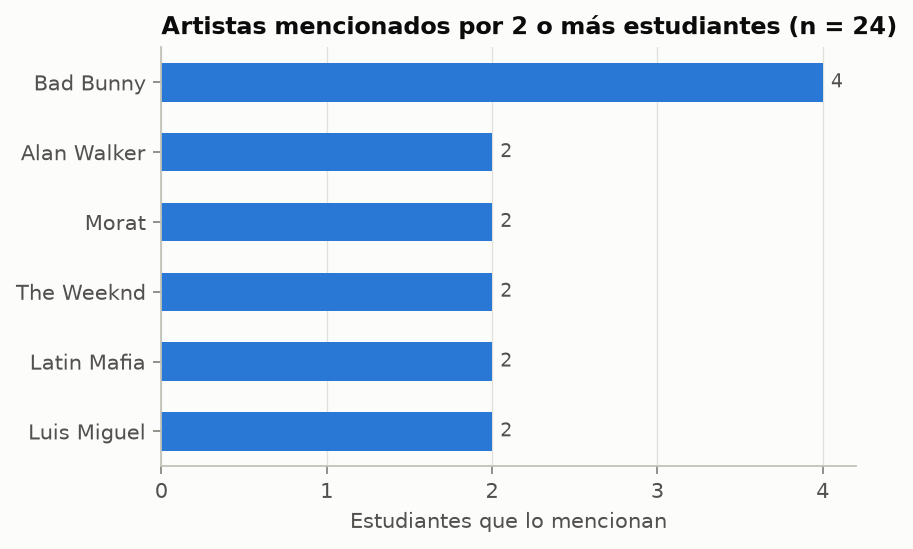

In [24]:
# Artistas mencionados por al menos 2 estudiantes (gráfica con seaborn y la misma paleta)
import seaborn as sns
from texto import artistas, frecuencias
top_artistas = artistas(dfs[1]["m_artistas"]).rename("menciones")
display(top_artistas.to_frame().T)
fig, ax = gr.plt.subplots(figsize=(5.6, 0.4 * len(top_artistas) + 1.0))
sns.barplot(x=top_artistas.values, y=[a.title() for a in top_artistas.index], color=gr.CATEGORICA[0], saturation=1,
            width=0.55, ax=ax)
for i, v in enumerate(top_artistas.values):
    ax.text(v + 0.05, i, f"{v}", va="center", fontsize=8.5, color=gr.TINTA_2)
ax.grid(axis="y", visible=False); ax.set_xlabel("Estudiantes que lo mencionan")
ax.xaxis.set_major_locator(gr.MaxNLocator(integer=True))
ax.set_title(f"Artistas mencionados por 2 o más estudiantes (n = {dfs[1]['m_artistas'].notna().sum()})")
mostrar(fig, "f14_artistas.png")

In [25]:
# Palabras y bigramas más frecuentes por pregunta abierta
for col, titulo, df in [("m_experiencia", "Experiencia en que una canción cambió el ánimo (Doc 1)", dfs[1]),
                        ("ia_verificacion", "Cómo verifican la información de la IA (Doc 3)", dfs[3]),
                        ("ia_cambio_estudio", "Cómo cambió su forma de estudiar con IA (Doc 3)", dfs[3]),
                        ("ia_reglas", "Reglas personales de uso de la IA (Doc 3)", dfs[3])]:
    display(Markdown(f"**{titulo}**"))
    display(frecuencias(df[col], n=8))

**Experiencia en que una canción cambió el ánimo (Doc 1)**

,palabra,frecuencia,respuestas,bigrama,frecuencia_bigrama
0,musica,9,8,estresada pongo,2.0
1,cancion,8,7,escuchar musica,2.0
2,siento,6,4,mientras ejercicio,2.0
3,pongo,5,5,,NaN
4,motiva,4,4,,NaN
5,ejercicio,3,3,,NaN
6,estaba,3,3,,NaN
7,humor,3,3,,NaN


**Cómo verifican la información de la IA (Doc 3)**

,palabra,frecuencia,respuestas,bigrama,frecuencia_bigrama
0,informacion,8,7,comparo informacion,3.0
1,fuentes,7,7,fuentes confiables,2.0
2,primero,5,5,primero comparo,2.0
3,reviso,3,3,informacion dio,2.0
4,clase,3,3,fuentes informacion,2.0
5,ver,3,3,,NaN
6,apuntes,3,3,,NaN
7,comparo,3,3,,NaN


**Cómo cambió su forma de estudiar con IA (Doc 3)**

,palabra,frecuencia,respuestas,bigrama,frecuencia_bigrama
0,estudiar,5,5,entender mejor,3.0
1,ahora,5,4,mejor temas,3.0
2,entender,4,4,ayudado entender,3.0
3,mejor,4,4,,NaN
4,temas,4,4,,NaN
5,rapido,4,4,,NaN
6,ayudado,3,3,,NaN
7,dudas,2,2,,NaN


**Reglas personales de uso de la IA (Doc 3)**

,palabra,frecuencia,respuestas,bigrama,frecuencia_bigrama
0,usarla,4,4,verificar informacion,2.0
1,utilizarla,3,3,,NaN
2,informacion,3,3,,NaN
3,entender,3,3,,NaN
4,resolver,3,3,,NaN
5,haga,3,3,,NaN
6,ninguno,3,3,,NaN
7,apoyo,2,2,,NaN


**Lectura:**

- **Artistas.** Los más mencionados son muy diversos (Bad Bunny es el único con 4 menciones), lo que confirma la variedad de géneros observada.
- **Experiencias con la música.** Se repiten "pongo", "motiva" y "ejercicio": los estudiantes usan la música de forma **deliberada** para activarse.
- **IA.** Al verificar la información, predominan "fuentes", "información" y "comparo" (por ejemplo, el bigrama "comparo información"). Al describir el cambio en su forma de estudiar, destacan "entender mejor los temas" y "rápido". Ambos patrones coinciden con la señal de que usar la IA como guía para comprender se asocia con menos estrés.

## 7. Hallazgos

**Calidad de la integración.** El núcleo conserva 19 estudiantes (79 % de los Documentos 1 y 3), sin indicios de sesgo de selección en los hábitos musicales ni en la mejora de ánimo. El conjunto música + IA conserva a los 24 estudiantes.

**Panorama descriptivo:**

- **Música:** es un hábito intenso (mediana de 4 h al día) y se escucha sobre todo en los traslados (75 %).
- **Mejora de ánimo:** el 85 % (17 de 20) reporta que la música mejora su ánimo.
- **Bienestar:** es más bien bajo. El 78 % tiene un IEP medio o alto, el desánimo es frecuente y el sueño suele ser malo.
- **IA:** el uso es moderado (mediana de 1.5 h) y casi todos la perciben como un alivio del estrés.
- **Traslados:** se asocian con peor calidad de sueño (ρ = −0.51).

**Evaluación de las hipótesis.** Ninguna asociación resiste la corrección de Benjamini-Hochberg. Con n ≈ 19, la potencia solo alcanza para detectar efectos grandes, así que la ausencia de significancia **no equivale a ausencia de relación**. Las señales exploratorias más consistentes son:

| Hipótesis | Señal | Lectura |
|-----------|-------|---------|
| H1 | Quienes reportan mejora tienen un IEP ligeramente menor (mediana 2.0 frente a 2.5; r = −0.33; *p* = 0.41) | Dirección coherente con la hipótesis, pero muy incierta: solo hay 3 casos sin mejora |
| H2 | Quienes reportan mejora escuchan más horas: mediana 5 frente a 1.5 h; r = 0.88; *p* = 0.019; *q* = 0.35; se mantiene sin atípicos (*p* = 0.021). Más horas se asocian con percibir que la música ayuda a concentrarse (ρ = 0.43) y da energía (ρ = 0.37; 0.51 sin atípicos) | El beneficio percibido crece con la intensidad de escucha. Uno de los 3 casos sin mejora no escucha música, lo que contribuye a la diferencia |
| H3 | Sin diferencias de IEP ni de mejora entre géneros | Los datos no respaldan que un género concreto se asocie con mejor bienestar |
| H4 | Quienes usan la IA **como guía para aprender** tienen un IEP menor (mediana 1.0 frente a 2.5; r = −0.68; *p* = 0.031; *q* = 0.35). Se mantiene sin atípicos (*p* = 0.037). Además, la relación entre horas de música e IEP cambia de signo según el uso de IA (ρ = +0.36 con poco uso frente a −0.57 con mucho uso) | Es la señal más fuerte del estudio y apunta a la modalidad de uso, no a la cantidad. La posible moderación es solo descriptiva |

**Disociación entre fuentes.** Los beneficios atribuidos a la música (Documento 1) casi no se correlacionan con los indicadores generales de bienestar (Documento 2). Esto sugiere que el efecto percibido de la música es **situacional e inmediato**, como acompañar un trayecto o una tarea, y no se refleja en el estado de ánimo general reportado.

**Limitaciones.** El tamaño muestral es reducido, los datos son auto-reportados y transversales, la codificación de texto libre implica decisiones del equipo, el IEP no es un instrumento validado y la etiqueta de mejora tiene muy poca variabilidad.

